In [63]:
from sklearn import datasets
import numpy as np
import seaborn as sns
import pandas as pd

In [64]:
iris=datasets.load_iris()

In [49]:
type(iris)
type(iris['data'])
print(type(iris['data']))
print(iris.keys())
print(iris.DESCR)

<class 'numpy.ndarray'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
==============

In [50]:
n_samples,n_features=iris.data.shape
n_samples
n_features

4

In [51]:
print(iris['data'].shape)

(150, 4)


In [52]:
len(iris.target)==n_samples

True

In [53]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [54]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [55]:
iris.data[0]

array([5.1, 3.5, 1.4, 0.2])

In [65]:
print(type(iris.data))
print(type(iris.target))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [57]:
x=iris.data
y=iris.target

In [58]:
%matplotlib inline

In [66]:
df=pd.DataFrame(iris.data, columns=iris.feature_names)

In [68]:
correlation=df.corr()
correlation

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


<Axes: >

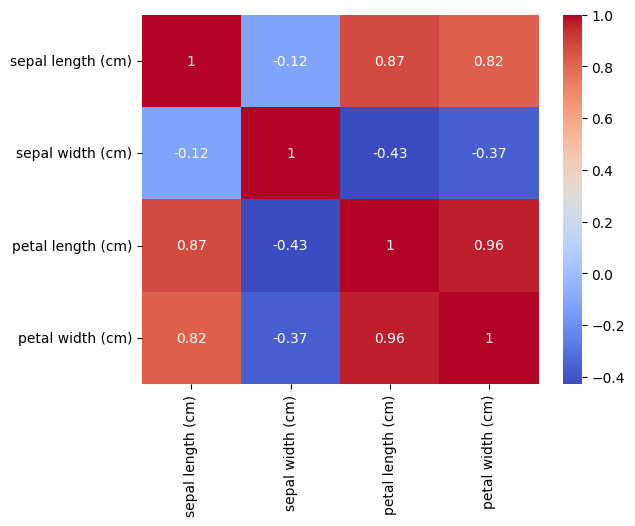

In [69]:
sns.heatmap(df.corr(),cmap='coolwarm',annot=True)

In [76]:
print(df.columns)
df.columns = ['sepal_length','sepal_width','petal_length','petal_width']
print(df.columns)

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width'], dtype='object')


In [87]:
df['species']=iris.target

In [90]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [89]:
df['species']=df['species'].map({0:'setosa',1:'versicolor',2:'virginica'})


In [ ]:
df

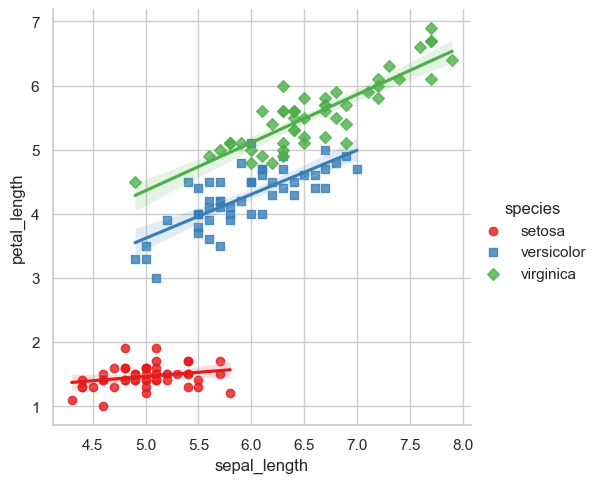

In [91]:
sns.set(style="whitegrid",color_codes=True)
sns.lmplot(
    x="sepal_length",
    y="petal_length",
    hue="species",
    data=df,
    palette="Set1",
    markers=["o","s","D"]
)

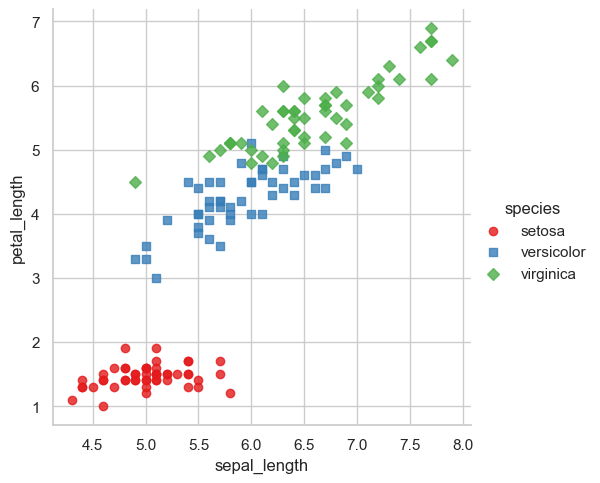

In [94]:
sns.lmplot(x="sepal_length", y="petal_length", hue="species", data = df, 
              palette="Set1", fit_reg=False, markers=["o", "s", "D"])

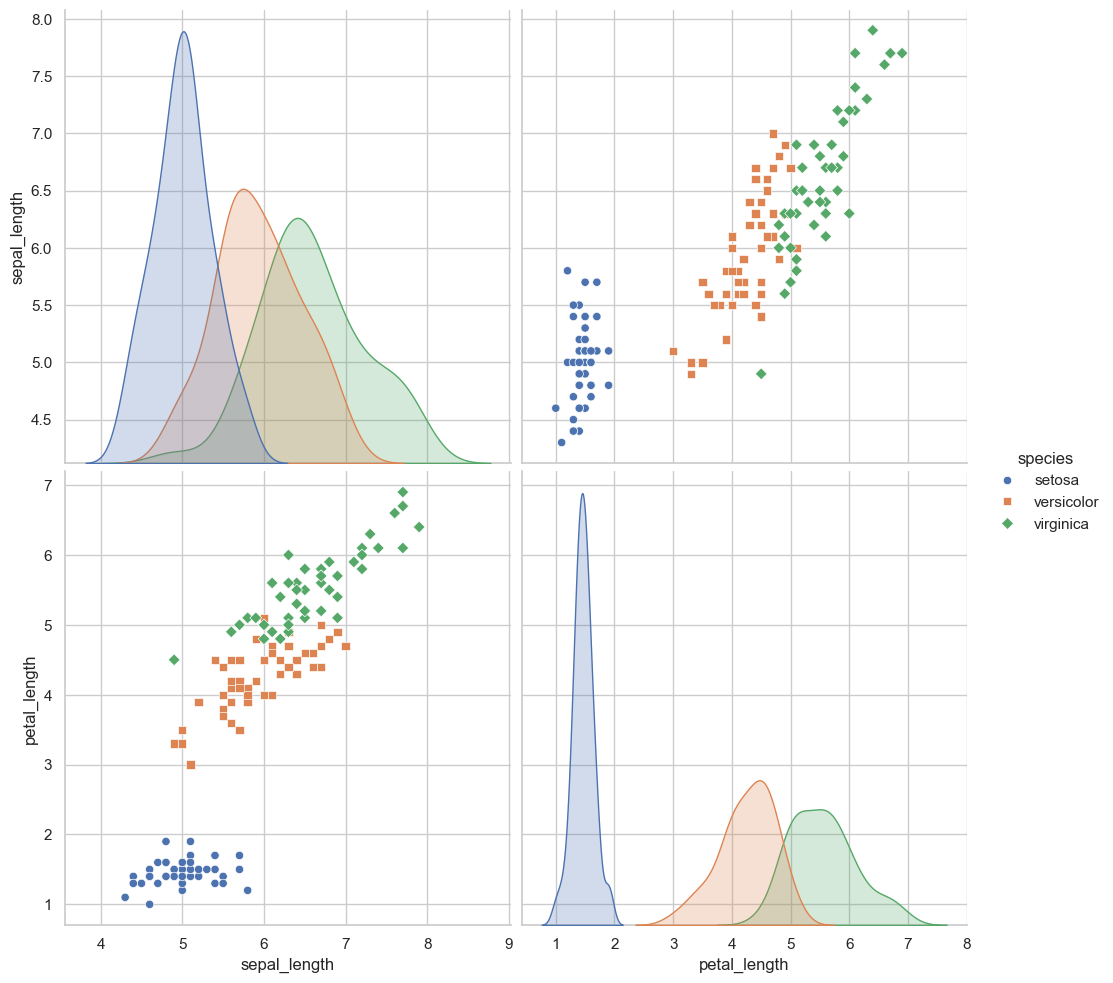

In [96]:
sns.pairplot(df, size=5, vars=["sepal_length", "petal_length"], 
             markers=["o", "s", "D"], hue="species")

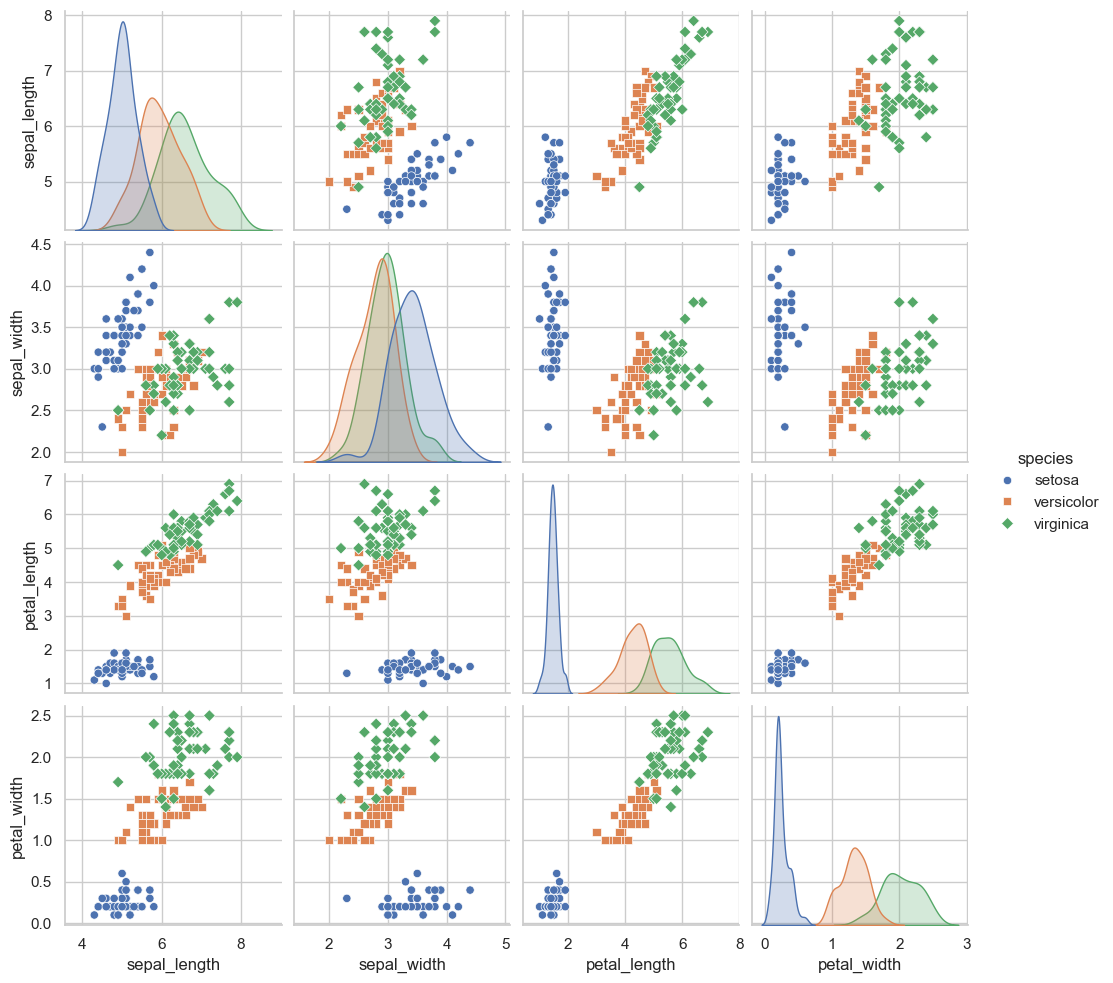

In [98]:
sns.pairplot(df, markers=["o", "s", "D"], hue="species")

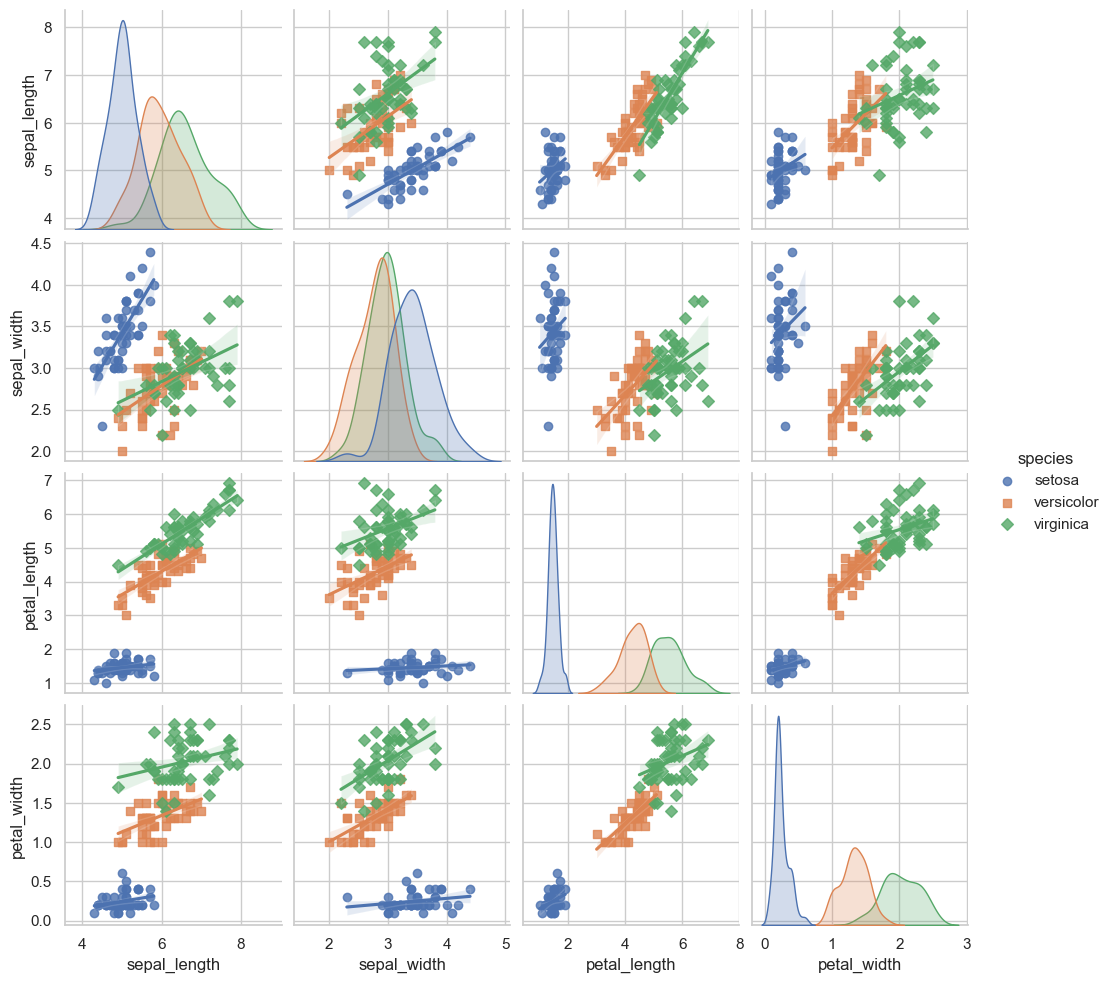

In [101]:
sns.pairplot(df, kind="reg", hue="species", markers=["o", "s", "D"])

<Axes: >

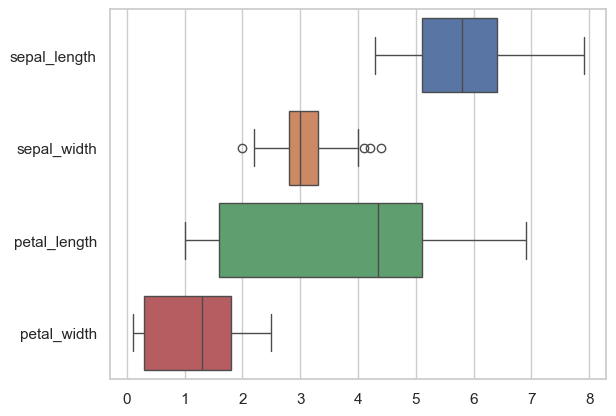

In [102]:
sns.boxplot(data = df, orient = "h")


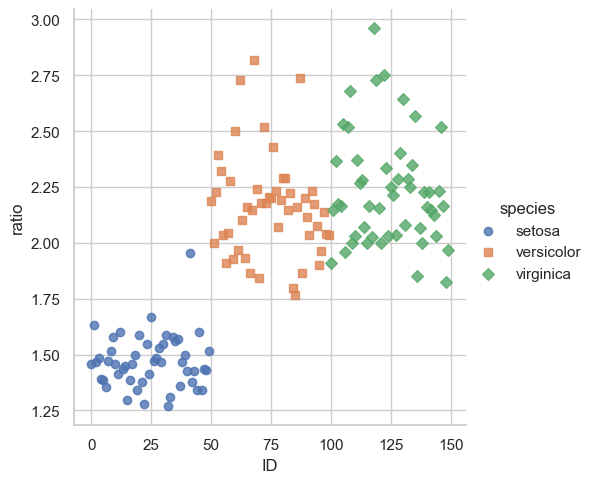

In [104]:
df["ID"] = df.index
df["ratio"] = df["sepal_length"]/df["sepal_width"]
sns.lmplot(x="ID", y="ratio", data=df, \
           hue="species", markers=["o", "s", "D"], fit_reg=False, legend=True)

<Axes: xlabel='species', ylabel='sepal_length'>

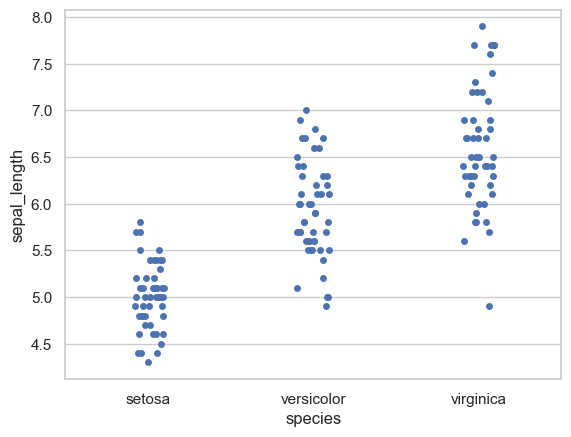

In [105]:
sns.stripplot(x = "species", y = "sepal_length", data = df)


<Axes: xlabel='species', ylabel='petal_length'>

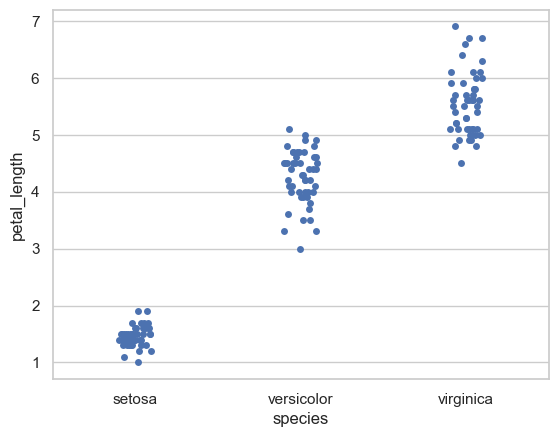

In [106]:
sns.stripplot(x = "species", y = "petal_length", data = df, jitter = True)


<Axes: xlabel='species', ylabel='petal_length'>

C:\Users\User\miniconda3\envs\ai_env\lib\site-packages\seaborn\categorical.py:3399: UserWarning: 12.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


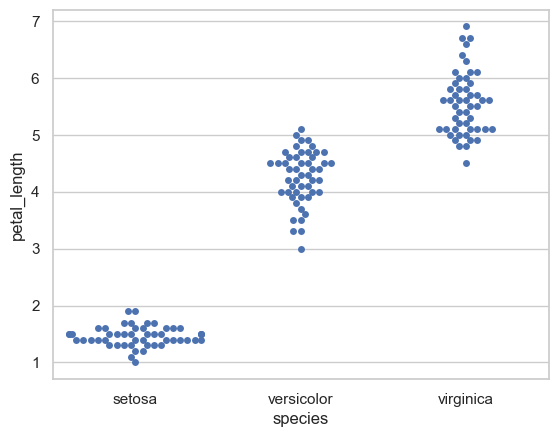

In [107]:
sns.swarmplot(x="species", y="petal_length", data=df)